# EcoPulse AI - Phase 4

## 1. Project Introduction

**Project:** EcoPulse AI - Intelligent Energy Consumption Monitoring,
Forecasting and Anomaly Detection System

**Tagline:** *Understand Energy. Predict Tomorrow. Optimise Smarter.*

**Notebook:** `03_energy_forecasting.ipynb`

This notebook documents the Phase 4 hourly forecasting experiment. It reads the
prepared hourly dataset derived from the Phase 3 Parquet outputs, the saved
predictions, the persisted model bundle and the real report artefacts. It does
not retrain the models and does not use future values.

The forecasting target is `total_energy_consumption_kwh` for complete
clock-hours only. An hour is supervised only when it contains exactly 60 valid
one-minute observations; incomplete and boundary hours keep a missing target
and are never treated as zero consumption.

## 2. Objectives

1. Verify the prepared dataset, target definition and chronological splits.
2. Confirm that every lag and rolling feature is causal.
3. Compare the five pre-specified forecasting candidates on validation RMSE.
4. Report the one-time test evaluation without re-selecting the model.
5. Reload the persisted Joblib bundle and reproduce its stored test predictions.
6. Present the real metrics, comparisons and figures produced by the pipeline.

Model selection uses the validation split only. The test split is evaluated once
after selection and is never used to change the deployed model.

## 3. Import Libraries and Locate the Project

The notebook discovers the repository root by walking up from the current
working directory, so it runs both from the project root and from
`data-engineering/notebooks/`. It imports the same feature constants and metric
functions used by the pipeline instead of redefining them.

In [1]:
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)


def find_project_root() -> Path:
    """Find the EcoPulse AI root from the notebook working directory."""
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / "machine-learning" / "utils" / "features.py").is_file()
            and (candidate / "reports" / "machine-learning").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the EcoPulse AI repository. "
        "Open this notebook from inside the project."
    )


def sha256sum(path: Path) -> str:
    """Return the SHA-256 digest of a file."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


PROJECT_ROOT = find_project_root()
MACHINE_LEARNING_DIR = PROJECT_ROOT / "machine-learning"
if str(MACHINE_LEARNING_DIR) not in sys.path:
    sys.path.insert(0, str(MACHINE_LEARNING_DIR))

from utils.features import FORECAST_FEATURES, TARGET_COLUMN  # noqa: E402
from utils.metrics import regression_metrics  # noqa: E402

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "ml"
MODEL_DIR = MACHINE_LEARNING_DIR / "models" / "forecasting"
REPORT_DIR = PROJECT_ROOT / "reports" / "machine-learning"
FIGURE_DIR = REPORT_DIR / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Forecast features: {len(FORECAST_FEATURES)}")
print(f"Target column: {TARGET_COLUMN}")
print(f"pandas {pd.__version__} | numpy {np.__version__}")

Project root: D:\ai\EcoPulse-AI
Forecast features: 24
Target column: target_energy_kwh
pandas 2.3.3 | numpy 2.5.5


## 4. Configuration and Required Artefacts

Every path is relative to the discovered project root. The notebook stops with a
clear message if the pipeline outputs are missing.

In [2]:
FORECAST_DATA_PATH = DATA_DIR / "forecasting_dataset.parquet"
PREDICTIONS_PATH = DATA_DIR / "forecasting_predictions.parquet"
PREPARATION_PATH = DATA_DIR / "preparation_summary.json"
TRAINING_SUMMARY_PATH = DATA_DIR / "forecasting_training_summary.json"
METRICS_PATH = REPORT_DIR / "forecasting_metrics.csv"
COMPARISON_PATH = REPORT_DIR / "forecasting_comparison.csv"
MODEL_PATH = MODEL_DIR / "best_forecasting_model.joblib"
METADATA_PATH = MODEL_DIR / "forecasting_metadata.json"
FEATURES_PATH = MODEL_DIR / "forecasting_features.json"

required_paths = {
    "prepared dataset": FORECAST_DATA_PATH,
    "saved predictions": PREDICTIONS_PATH,
    "preparation summary": PREPARATION_PATH,
    "training summary": TRAINING_SUMMARY_PATH,
    "metrics CSV": METRICS_PATH,
    "comparison CSV": COMPARISON_PATH,
    "model bundle": MODEL_PATH,
    "model metadata": METADATA_PATH,
    "feature list": FEATURES_PATH,
}
missing = [name for name, path in required_paths.items() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing Phase 4 forecasting outputs: " + ", ".join(missing)
        + ". Run machine-learning/src/06_run_ml_pipeline.py first."
    )

dataset = pd.read_parquet(FORECAST_DATA_PATH)
predictions = pd.read_parquet(PREDICTIONS_PATH)
preparation = json.loads(PREPARATION_PATH.read_text(encoding="utf-8"))
training_summary = json.loads(TRAINING_SUMMARY_PATH.read_text(encoding="utf-8"))
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
feature_document = json.loads(FEATURES_PATH.read_text(encoding="utf-8"))
metrics = pd.read_csv(METRICS_PATH)
comparison = pd.read_csv(COMPARISON_PATH)

actual_hash = sha256sum(FORECAST_DATA_PATH)
assert actual_hash == metadata["dataset_sha256"], "Forecast dataset hash changed."
print(f"Rows loaded:          {len(dataset):,}")
print(f"Prediction rows:      {len(predictions):,}")
print(f"Models in summary:    {len(training_summary['models'])}")
print(f"Dataset SHA-256:      {actual_hash[:24]}... (matches metadata)")

Rows loaded:          34,589
Prediction rows:      157,255
Models in summary:    5
Dataset SHA-256:      ffd3d5c8c55643f49a051fdf... (matches metadata)


## 5. Prepared Data and Target

The hourly grid contains both complete and incomplete hours. Only complete hours
enter supervision; feature warm-up rows have no split label and no target. The
verify cell below checks these invariants directly from the saved dataset.

In [3]:
modeling = dataset.loc[dataset["is_modeling_row"]].copy()
train_rows = int((dataset["split"] == "train").sum())
validation_rows = int((dataset["split"] == "validation").sum())
test_rows = int((dataset["split"] == "test").sum())

split_table = (
    modeling.groupby("split", observed=True)
    .agg(
        rows=("timestamp", "size"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        target_mean=(TARGET_COLUMN, "mean"),
    )
    .reindex(["train", "validation", "test"])
)
split_table["rows"] = split_table["rows"].map("{:,}".format)
split_table["target_mean"] = split_table["target_mean"].map("{:.4f}".format)
display(split_table)

forecast_summary = preparation["forecasting"]
summary_table = pd.DataFrame(
    {
        "value": [
            f"{forecast_summary['hourly_intervals']:,}",
            f"{forecast_summary['complete_hours']:,}",
            f"{forecast_summary['incomplete_hours']:,}",
            f"{forecast_summary['empty_hours']:,}",
            f"{forecast_summary['modeling_rows']:,}",
            f"{forecast_summary['warmup_excluded_rows']:,}",
        ]
    },
    index=[
        "Hourly intervals",
        "Complete hours",
        "Incomplete hours",
        "Empty hours",
        "Supervised modelling rows",
        "Warm-up / incomplete rows excluded",
    ],
)
display(summary_table)

target = modeling[TARGET_COLUMN]
print("Target definition:")
print(metadata["target_definition"])
print(
    f"Target range: {target.min():.4f} - {target.max():.4f} kWh | "
    f"mean {target.mean():.4f} | median {target.median():.4f}"
)

assert len(modeling) == forecast_summary["modeling_rows"]
assert target.notna().all() and (target > 0).all()
assert train_rows == training_summary["splits"][0]["rows"]
assert validation_rows == training_summary["splits"][1]["rows"]
assert test_rows == training_summary["splits"][2]["rows"]
assert dataset.loc[dataset["is_modeling_row"], "split"].notna().all()
assert dataset.loc[~dataset["is_modeling_row"], "split"].isna().all()
print("Data invariants checked: target complete/positive and splits aligned.")

,rows,start,end,target_mean
split,,,,
train,"22,015",2006-12-23 18:00:00,2009-09-19 05:00:00,1.0903
validation,"4,717",2009-09-19 06:00:00,2010-04-21 11:00:00,1.2474
test,"4,719",2010-04-21 12:00:00,2010-11-26 20:00:00,0.9529


,value
Hourly intervals,"34,589"
Complete hours,"34,141"
Incomplete hours,448
Empty hours,421
Supervised modelling rows,"31,451"
Warm-up / incomplete rows excluded,"3,138"


Target definition:
Total energy consumption (kWh) of one complete clock-hour with exactly 60 valid one-minute observations. Incomplete hours are missing targets, never zero consumption.
Target range: 0.1240 - 6.5605 kWh | mean 1.0932 | median 0.8043
Data invariants checked: target complete/positive and splits aligned.


## 6. Causal Features and Split Boundaries

The 24 features cover calendar context, cyclical encodings, past targets and
past rolling statistics. Every lag and rolling value is built from observations
strictly before the forecasted hour.

In [4]:
feature_rows = [
    {
        "group": group.title(),
        "count": len(columns),
        "features": ", ".join(columns),
    }
    for group, columns in feature_document["feature_groups"].items()
]
display(pd.DataFrame(feature_rows))

print(feature_document["causality"])
print()
for row in training_summary["splits"]:
    print(
        f"{row['split']:<10} {row['rows']:>7,} rows  "
        f"{row['start'][:19]} -> {row['end'][:19]}"
    )
print()
print("Chronological policy: 70% train / 15% validation / 15% test, no shuffle.")
assert len(FORECAST_FEATURES) == feature_document["feature_count"] if "feature_count" in feature_document else True
assert sum(len(columns) for columns in feature_document["feature_groups"].values()) == len(FORECAST_FEATURES)
print("All 24 declared features are present in the feature groups.")

,group,count,features
0,Time,7,"hour, day_of_week, day_of_month, day_of_year, ..."
1,Cyclical,6,"hour_sin, hour_cos, dow_sin, dow_cos, month_si..."
2,Lag,6,"lag_1, lag_2, lag_3, lag_24, lag_48, lag_168"
3,Rolling,5,"rolling_mean_3, rolling_mean_6, rolling_mean_2..."


Every lag and rolling statistic is computed from values strictly before the forecasted hour; rolling windows are shifted by one hour first.

train       22,015 rows  2006-12-23T18:00:00 -> 2009-09-19T05:00:00
validation   4,717 rows  2009-09-19T06:00:00 -> 2010-04-21T11:00:00
test         4,719 rows  2010-04-21T12:00:00 -> 2010-11-26T20:00:00

Chronological policy: 70% train / 15% validation / 15% test, no shuffle.
All 24 declared features are present in the feature groups.


## 7. Validation Metrics and Model Selection

Validation RMSE is the selection metric declared before training. MAE is shown
for interpretation, R2 for explained variance, and MAPE/sMAPE for relative error.
MAPE is only reported because every evaluated complete-hour target is non-zero.

In [5]:
METRIC_COLUMNS = [
    "model", "n", "mae", "rmse", "r2", "mape_pct", "smape_pct", "zero_actuals"
]
MODEL_ORDER = list(training_summary["models"])


def metric_table(split: str):
    subset = (
        metrics.loc[metrics["split"] == split, METRIC_COLUMNS]
        .set_index("model")
        .reindex(MODEL_ORDER)
    )
    return subset.style.format(
        {
            "n": "{:,}",
            "mae": "{:.4f}",
            "rmse": "{:.4f}",
            "r2": "{:.4f}",
            "mape_pct": "{:.2f}",
            "smape_pct": "{:.2f}",
            "zero_actuals": "{:,}",
        },
        na_rep="N/A",
    ).set_caption(f"{split.title()} metrics")


for split in ("train", "validation", "test"):
    display(metric_table(split))

ranking = comparison.sort_values("validation_rank").reset_index(drop=True)
display(
    ranking[
        [
            "validation_rank",
            "model",
            "selected_best",
            "validation_mae",
            "validation_rmse",
            "validation_r2",
            "test_mae",
            "test_rmse",
            "test_r2",
        ]
    ].style.format(
        {
            "validation_mae": "{:.4f}",
            "validation_rmse": "{:.4f}",
            "validation_r2": "{:.4f}",
            "test_mae": "{:.4f}",
            "test_rmse": "{:.4f}",
            "test_r2": "{:.4f}",
        }
    ).set_caption("Validation ranking with the one-time test results")
)

assert ranking.iloc[0]["model"] == training_summary["best_model"]
assert bool(ranking.iloc[0]["selected_best"])
print(f"Selected model by validation RMSE: {training_summary['best_model']}")

,n,mae,rmse,r2,mape_pct,smape_pct,zero_actuals
model,,,,,,,
Naive (lag 1),"22,015",0.4496,0.7008,0.4351,49.20,39.72,0
Seasonal Naive (lag 24),"22,015",0.6600,0.9865,-0.1193,85.67,56.18,0
Linear Regression,"22,015",0.4178,0.6007,0.5850,56.62,41.91,0
Random Forest,"22,015",0.1690,0.2595,0.9225,21.69,18.34,0
HistGradientBoosting,"22,015",0.2911,0.4261,0.7912,37.85,30.42,0


,n,mae,rmse,r2,mape_pct,smape_pct,zero_actuals
model,,,,,,,
Naive (lag 1),"4,717",0.4659,0.6927,0.3941,45.05,37.80,0
Seasonal Naive (lag 24),"4,717",0.6723,0.9672,-0.1812,76.41,52.91,0
Linear Regression,"4,717",0.4207,0.5854,0.5673,48.71,37.30,0
Random Forest,"4,717",0.3736,0.5390,0.6332,40.87,31.95,0
HistGradientBoosting,"4,717",0.3776,0.5454,0.6245,40.90,32.07,0


,n,mae,rmse,r2,mape_pct,smape_pct,zero_actuals
model,,,,,,,
Naive (lag 1),"4,719",0.3845,0.5828,0.3215,46.32,38.62,0
Seasonal Naive (lag 24),"4,719",0.5112,0.7592,-0.1512,67.35,49.35,0
Linear Regression,"4,719",0.3540,0.4986,0.5034,48.32,38.43,0
Random Forest,"4,719",0.3194,0.4626,0.5726,43.73,34.16,0
HistGradientBoosting,"4,719",0.3208,0.4653,0.5677,43.76,34.43,0


,validation_rank,model,selected_best,validation_mae,validation_rmse,validation_r2,test_mae,test_rmse,test_r2
0,1,Random Forest,True,0.3736,0.5390,0.6332,0.3194,0.4626,0.5726
1,2,HistGradientBoosting,False,0.3776,0.5454,0.6245,0.3208,0.4653,0.5677
2,3,Linear Regression,False,0.4207,0.5854,0.5673,0.3540,0.4986,0.5034
3,4,Naive (lag 1),False,0.4659,0.6927,0.3941,0.3845,0.5828,0.3215
4,5,Seasonal Naive (lag 24),False,0.6723,0.9672,-0.1812,0.5112,0.7592,-0.1512


Selected model by validation RMSE: Random Forest


## 8. Selected Model and Reload Verification

The persisted bundle is loaded from disk and asked to predict the saved test
features. Its output is compared with the stored predictions and the metrics are
recomputed from those predictions. This confirms that the deployed artefact is
reproducible and not a placeholder.

In [6]:
best_name = training_summary["best_model"]
best_row = comparison.loc[comparison["model"] == best_name].iloc[0]
bundle = joblib.load(MODEL_PATH)

print(f"Selected model:          {best_name}")
print(f"Bundle model name:       {bundle['model_name']}")
print(f"Model type:              {metadata['model_type']}")
print(f"Trained (UTC):           {metadata['training_date_utc']}")
print(f"Validation RMSE:         {best_row['validation_rmse']:.4f} kWh")
print(f"Test RMSE:               {best_row['test_rmse']:.4f} kWh")
print(f"Selection metric:        {metadata['selection_metric']}")
print(f"Preprocessing:           {metadata['preprocessing']}")

test_features = (
    modeling.loc[modeling["split"] == "test"].sort_values("timestamp").reset_index(drop=True)
)
stored_test = (
    predictions.loc[
        (predictions["model"] == best_name) & (predictions["split"] == "test")
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)
assert len(test_features) == len(stored_test)
assert np.array_equal(
    test_features["timestamp"].to_numpy(), stored_test["timestamp"].to_numpy()
)

reloaded_predictions = np.asarray(
    bundle["model"].predict(test_features[FORECAST_FEATURES]), dtype=float
)
max_difference = float(
    np.max(np.abs(reloaded_predictions - stored_test["predicted"].to_numpy(dtype=float)))
)
assert max_difference <= 1e-6

recomputed = regression_metrics(stored_test["actual"], stored_test["predicted"])
print(f"Test rows compared:      {len(stored_test):,}")
print(f"Max prediction diff:     {max_difference:.3e}")
print(
    "Recomputed test metrics: "
    f"MAE {recomputed['mae']:.4f} | RMSE {recomputed['rmse']:.4f} | "
    f"R2 {recomputed['r2']:.4f} | MAPE {recomputed['mape_pct']:.2f}% | "
    f"sMAPE {recomputed['smape_pct']:.2f}%"
)
print(
    "Metadata test metrics:   "
    f"MAE {metadata['test_metrics']['mae']:.4f} | "
    f"RMSE {metadata['test_metrics']['rmse']:.4f} | "
    f"R2 {metadata['test_metrics']['r2']:.4f}"
)

for key in ("mae", "rmse", "r2"):
    difference = abs(float(metadata["test_metrics"][key]) - float(recomputed[key]))
    assert difference <= 1e-9, f"Metadata metric mismatch for {key}: {difference}"
print("Saved metadata metrics match predictions exactly.")

Selected model:          Random Forest
Bundle model name:       Random Forest
Model type:              RandomForestRegressor
Trained (UTC):           2026-11-19T06:35:30.312902+00:00
Validation RMSE:         0.5390 kWh
Test RMSE:               0.4626 kWh
Selection metric:        validation RMSE
Preprocessing:           none required


Test rows compared:      4,719
Max prediction diff:     1.332e-15
Recomputed test metrics: MAE 0.3194 | RMSE 0.4626 | R2 0.5726 | MAPE 43.73% | sMAPE 34.16%
Metadata test metrics:   MAE 0.3194 | RMSE 0.4626 | R2 0.5726
Saved metadata metrics match predictions exactly.


## 9. Key Findings

The numbers below are read from the saved comparison table. They are not typed
into the notebook and will update if the pipeline is rerun.

In [7]:
seasonal = comparison.loc[comparison["model"] == "Seasonal Naive (lag 24)"].iloc[0]
naive = comparison.loc[comparison["model"] == "Naive (lag 1)"].iloc[0]
lowest_test = comparison.sort_values("test_rmse").iloc[0]

print(f"Best validation model:            {best_name}")
print(
    f"Validation RMSE improvement vs seasonal naive: "
    f"{best_row['validation_rmse_improvement_vs_seasonal_pct']:.2f}%"
)
print(
    f"Test RMSE improvement vs seasonal naive:       "
    f"{best_row['test_rmse_improvement_vs_seasonal_pct']:.2f}%"
)
print(
    f"Validation RMSE improvement vs lag-1 naive:    "
    f"{best_row['validation_rmse_improvement_vs_naive_pct']:.2f}%"
)
print(
    f"Lowest test RMSE model:           {lowest_test['model']} "
    f"({lowest_test['test_rmse']:.4f} kWh)"
)
if lowest_test["model"] != best_name:
    print("Note: the test result is reported passively and did not change the selected model.")
else:
    print("The validation-selected model also had the lowest test RMSE.")

print(
    f"Train rows: {train_rows:,} | validation rows: {validation_rows:,} | "
    f"test rows: {test_rows:,}"
)

Best validation model:            Random Forest
Validation RMSE improvement vs seasonal naive: 44.27%
Test RMSE improvement vs seasonal naive:       39.07%
Validation RMSE improvement vs lag-1 naive:    22.19%
Lowest test RMSE model:           Random Forest (0.4626 kWh)
The validation-selected model also had the lowest test RMSE.
Train rows: 22,015 | validation rows: 4,717 | test rows: 4,719


## 10. Real Evaluation Figures

These PNG files were generated by `03_evaluate_forecasting_models.py` from the
saved predictions and the prepared dataset. They are displayed here rather than
recreated with different logic.

**forecasting_actual_vs_predicted.png**

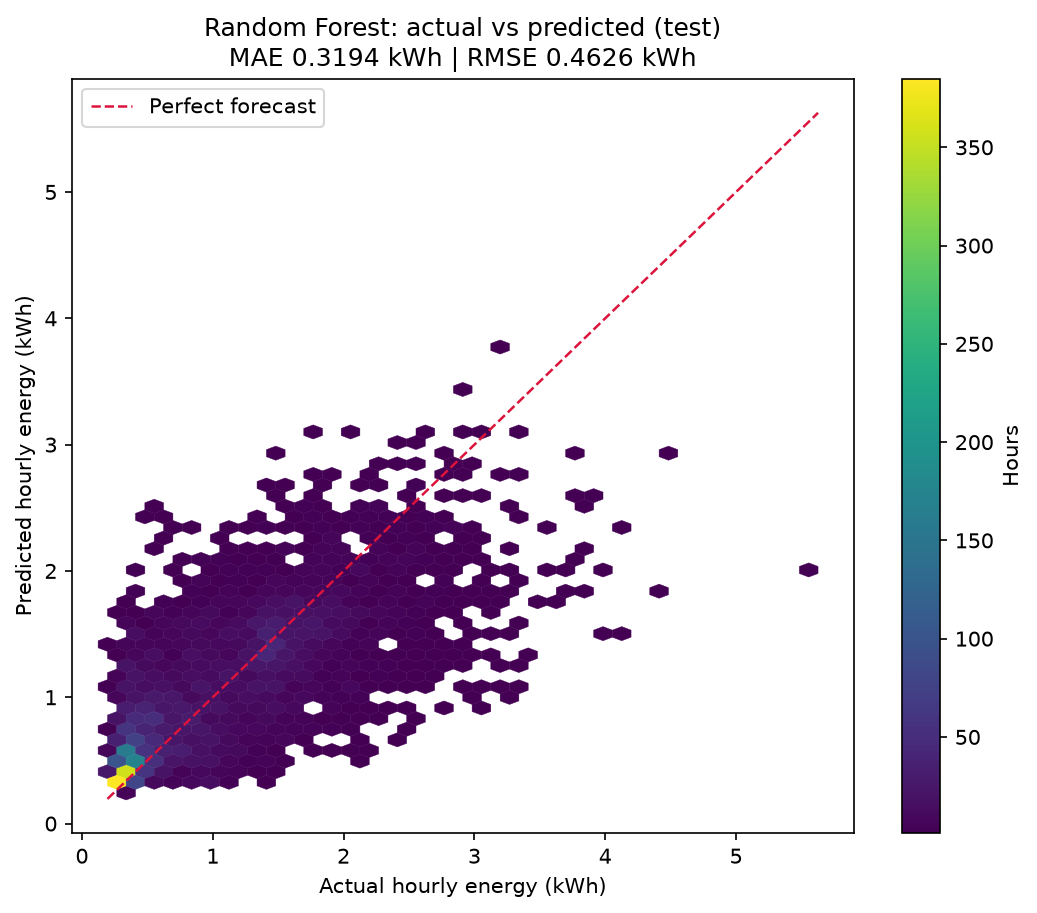

**forecasting_model_comparison.png**

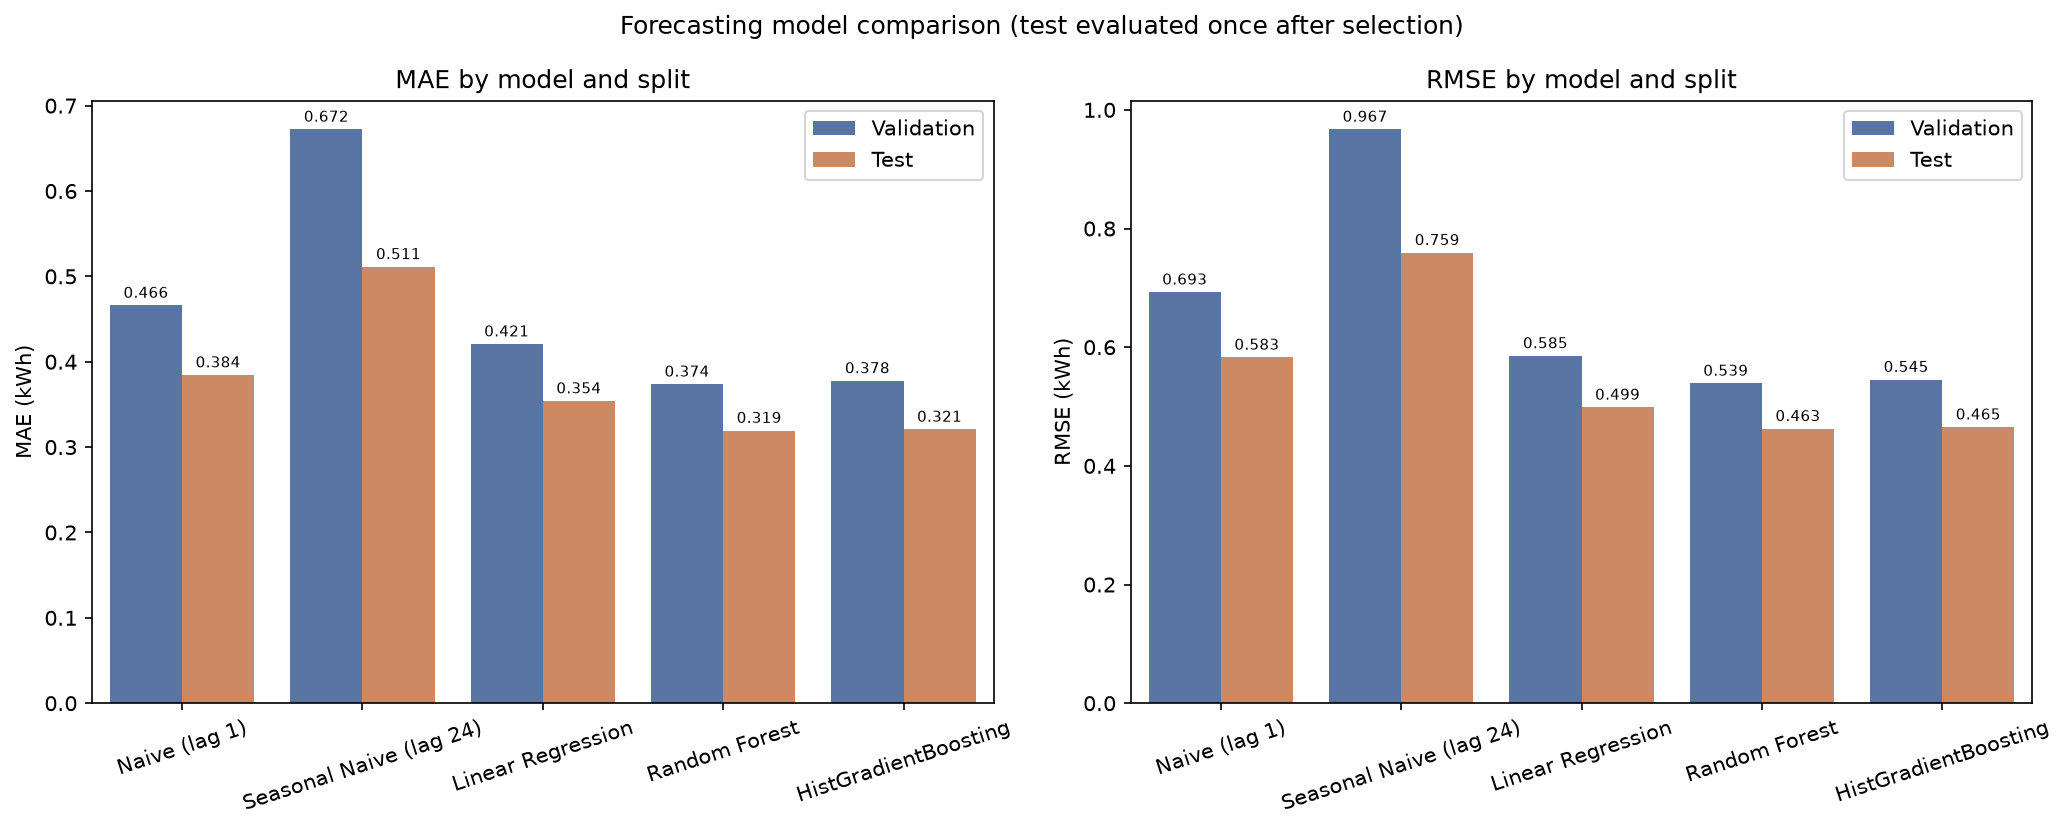

**forecasting_error_distribution.png**

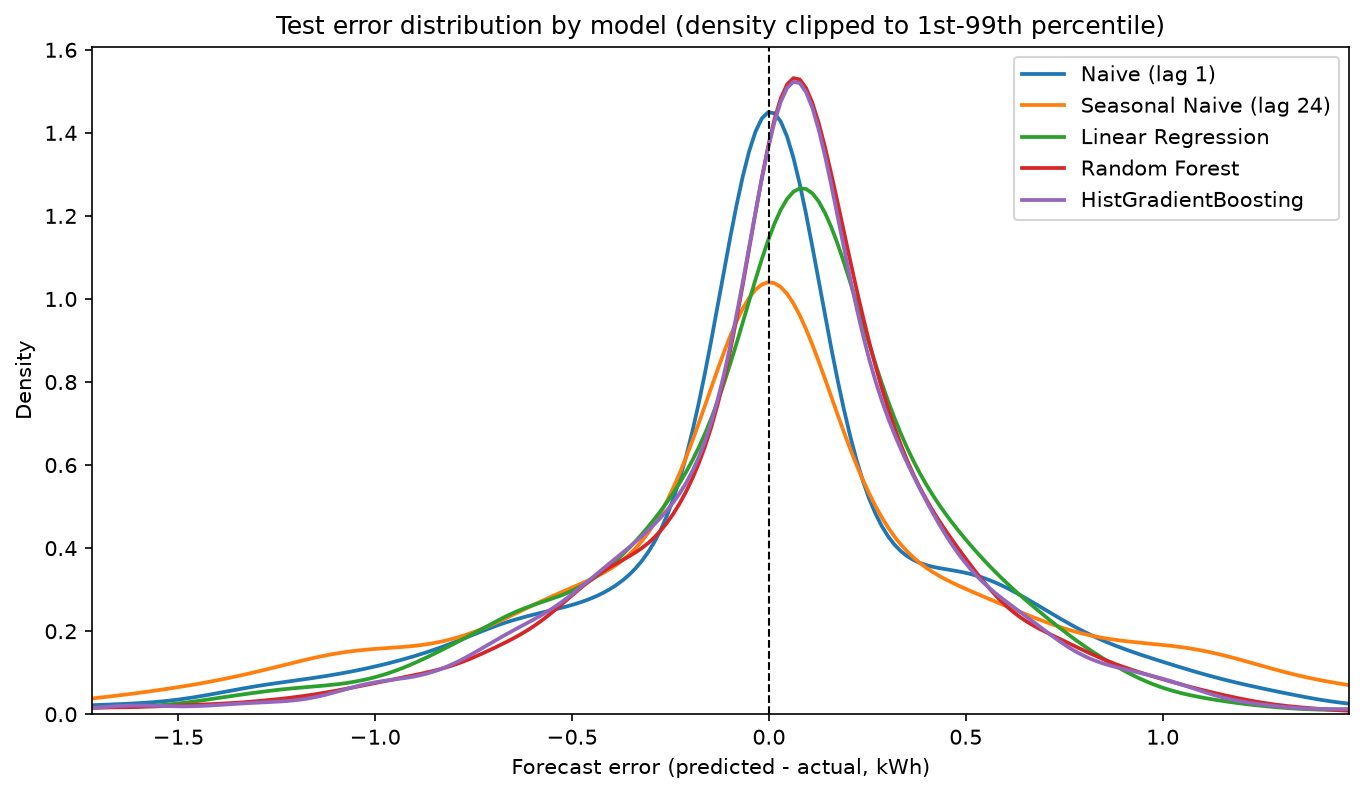

**forecasting_residual_analysis.png**

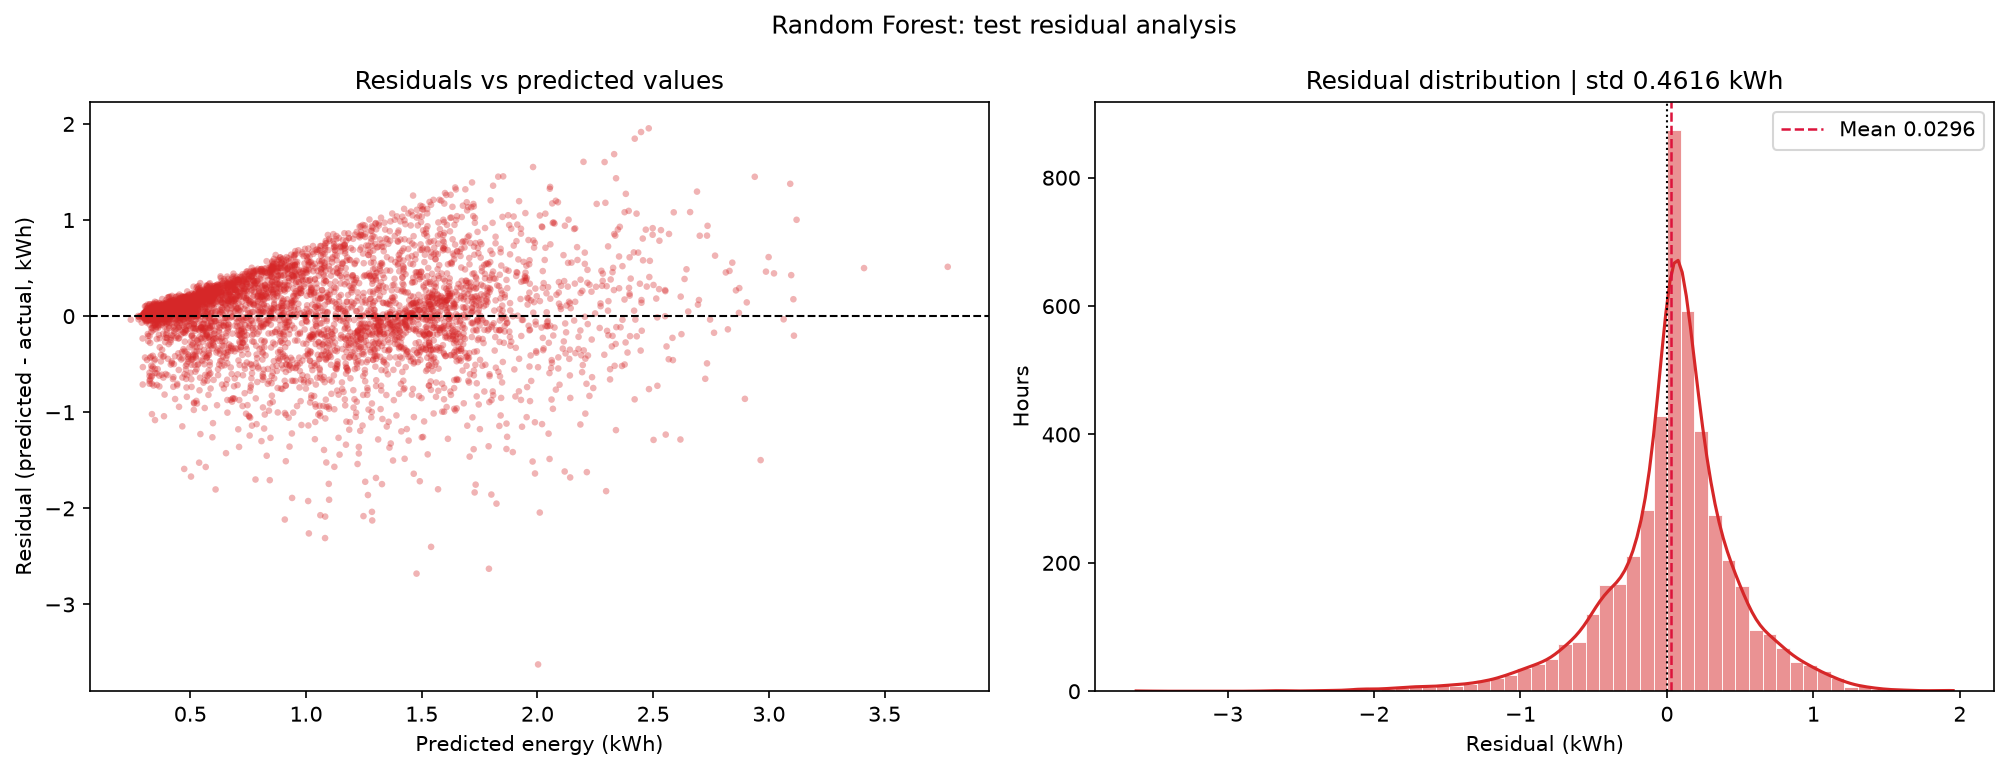

**forecasting_performance_over_time.png**

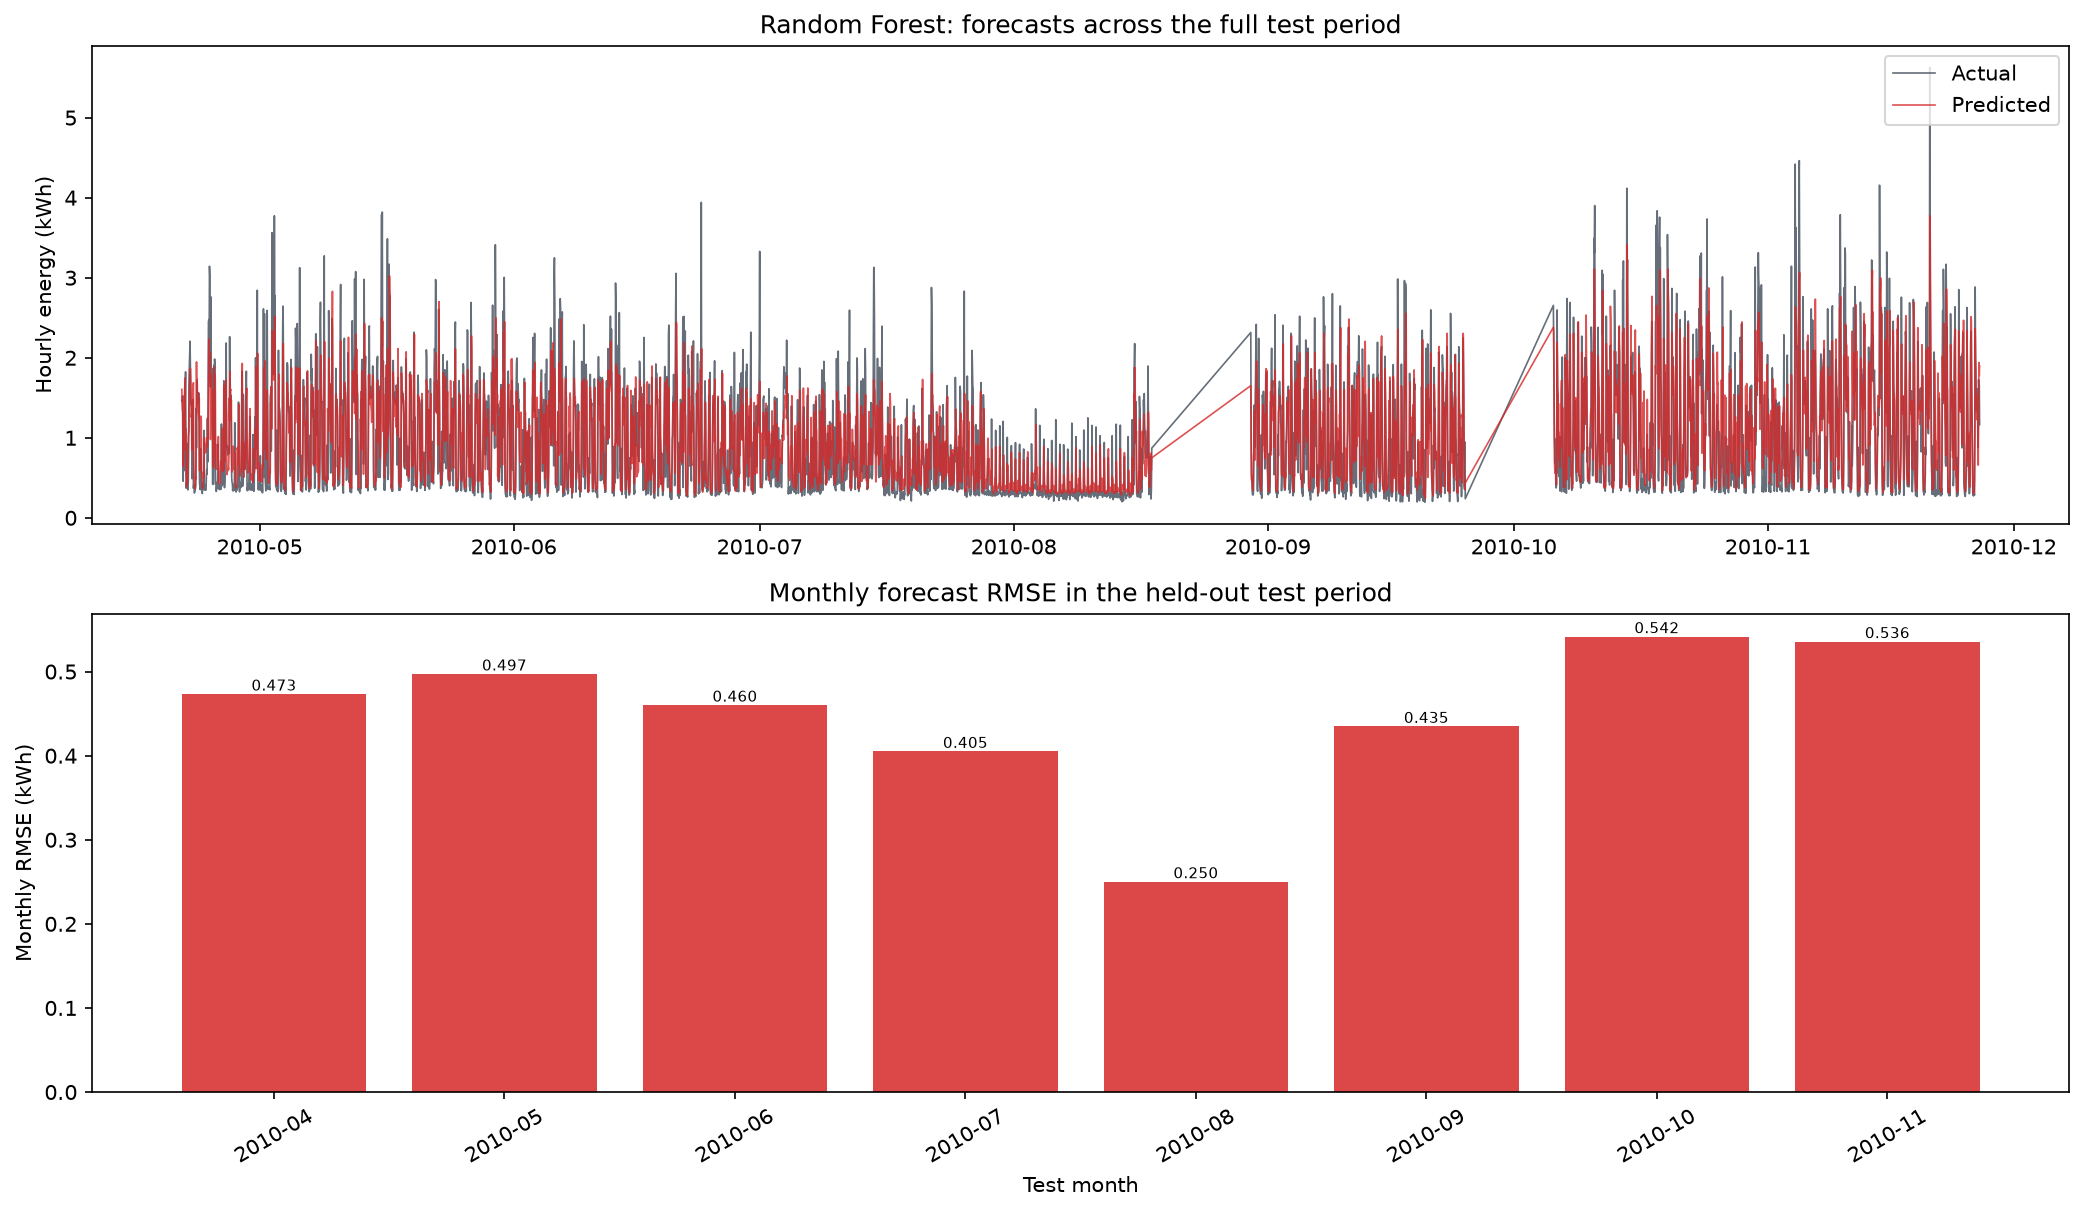

**forecasting_feature_importance.png**

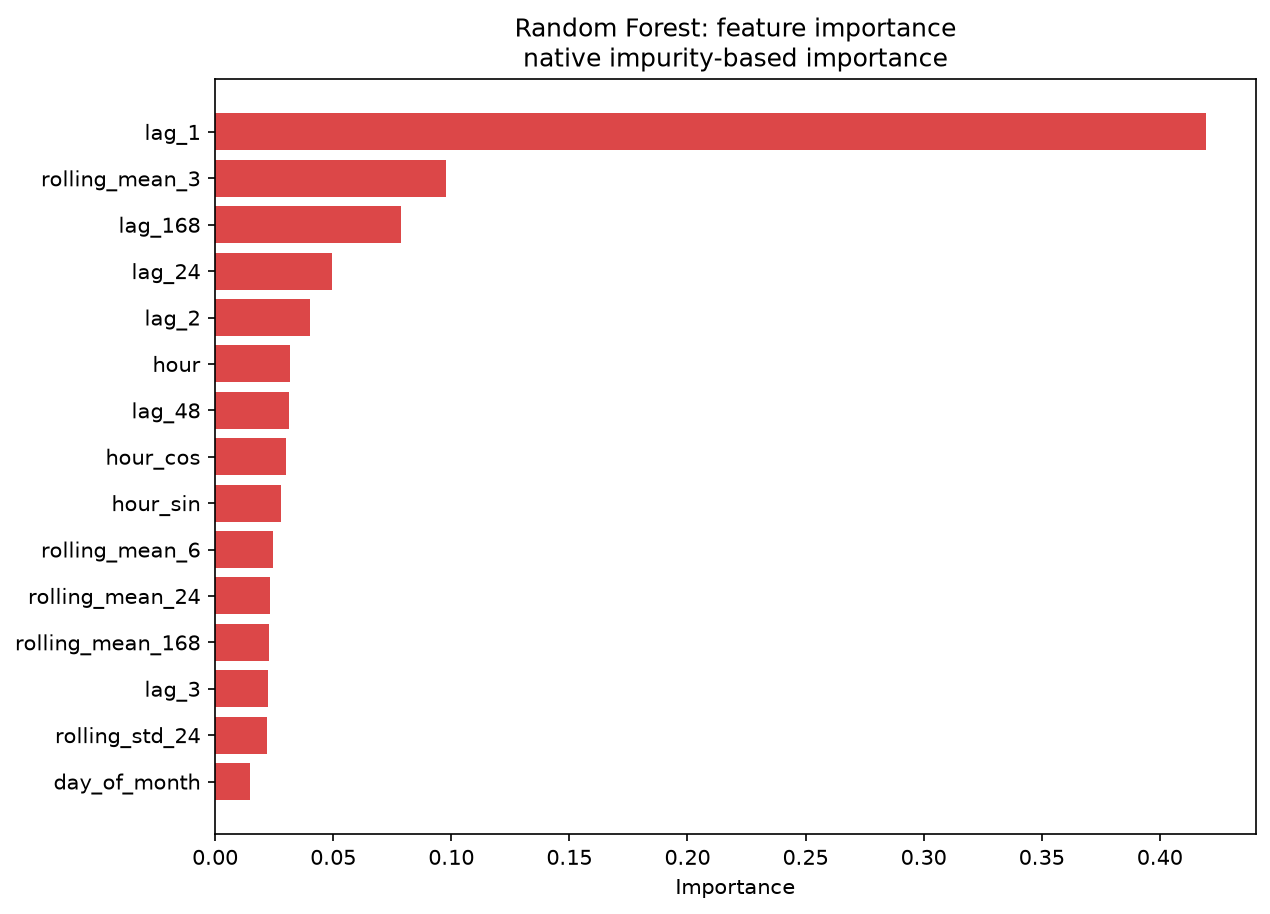

In [8]:
forecast_figures = [
    "forecasting_actual_vs_predicted.png",
    "forecasting_model_comparison.png",
    "forecasting_error_distribution.png",
    "forecasting_residual_analysis.png",
    "forecasting_performance_over_time.png",
    "forecasting_feature_importance.png",
]
for filename in forecast_figures:
    path = FIGURE_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing forecasting figure: {path}")
    display(Markdown(f"**{filename}**"))
    display(Image(filename=str(path), width=1100))

## 11. Interpretation and Limitations

**What the experiment shows**

- A chronological, leakage-safe hourly forecast is feasible from the Phase 3
  aggregates.
- The validation-selected model is evaluated once on the later test period and
  is compared honestly with persistence and seasonal-persistence baselines.
- The saved Joblib bundle reproduces the stored test predictions, so the reported
  metrics belong to the persisted artefact.

**Limitations**

- One household in France (2006-2010) is modelled; the result is not a
  cross-household generalisation claim.
- The evaluation uses one chronological hold-out, not rolling-origin backtests.
- No weather, occupancy, holiday, appliance or tariff variables are available.
- Feature warm-up and incomplete hours are excluded, so the evaluated period is
  not a random sample of the original timeline.
- The forecast horizon is one hour ahead from observed history; recursive
  multi-day forecasting was not evaluated.
- Hyperparameters were fixed a priori rather than tuned exhaustively.
- Tree models cannot extrapolate to consumption levels outside their training
  range. MAPE is sensitive when consumption is close to zero even when it is
  mathematically defined.

## 12. Notebook Verification Checklist

A final independent pass checks the key invariants before the notebook closes.

In [9]:
checklist = pd.DataFrame(
    [
        {"check": "Dataset SHA-256 matches model metadata", "passed": actual_hash == metadata["dataset_sha256"]},
        {"check": "All modelling targets are complete and positive", "passed": bool(target.notna().all() and (target > 0).all())},
        {"check": "Chronological splits are aligned with the summary", "passed": train_rows == training_summary["splits"][0]["rows"] and validation_rows == training_summary["splits"][1]["rows"] and test_rows == training_summary["splits"][2]["rows"]},
        {"check": "Validation ranking matches the selected model", "passed": ranking.iloc[0]["model"] == best_name},
        {"check": "Reloaded model reproduces test predictions", "passed": max_difference <= 1e-6},
        {"check": "Metadata test metrics match saved predictions", "passed": all(abs(float(metadata["test_metrics"][key]) - float(recomputed[key])) <= 1e-9 for key in ("mae", "rmse", "r2"))},
    ]
)
display(checklist)
assert checklist["passed"].all()
print("All notebook checks passed. No value was hard-coded from a previous run.")

,check,passed
0,Dataset SHA-256 matches model metadata,True
1,All modelling targets are complete and positive,True
2,Chronological splits are aligned with the summary,True
3,Validation ranking matches the selected model,True
4,Reloaded model reproduces test predictions,True
5,Metadata test metrics match saved predictions,True


All notebook checks passed. No value was hard-coded from a previous run.
